In [ ]:
## import the required dependencies
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
import seaborn as sns
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
## load the dataset here use your local folder wherever DronePropA dataset is stored instead of ./data
drone_dir = r"./data"

In [ ]:
## set the hyperparameters
batch_size = 512
epochs=50
lr=0.001
weight_decay=0.001
window_len=1000
model_variant=1
num_classes=4
eps=1e-5

In [ ]:
## generate time frequency windows 
def generate_time_freq_windows(signal_matrix, window_len):

    time_windows = []
    freq_windows = []

    total_samples = signal_matrix.shape[1]
    num_windows = total_samples // window_len

    mean = np.mean(signal_matrix, axis=1, keepdims=True)
    
    mean_shift_matrix = signal_matrix - mean

    for i in range(num_windows):

        k_start = i * window_len
        k_end = (i + 1) * window_len

        time_segment = mean_shift_matrix[:, k_start:k_end].astype(np.float32)
        freq_segment = np.abs(np.fft.fft(time_segment, axis=1)) / window_len
        freq_segment = freq_segment.astype(np.float32)

        time_windows.append(time_segment)
        freq_windows.append(freq_segment)

    return np.array(time_windows), np.array(freq_windows)
   

In [ ]:
## load the dataset
def load_multi_sensor_dataset(data_dir):

    X_time_segments = []
    X_freq_segments = []
    y_labels = []

    mat_files = glob.glob(os.path.join(data_dir, "**", "*.mat"), recursive=True)

    target_indices = [29, 30, 31, 26, 27, 28, 35, 36, 37, 46, 48, 50, 52]

    for fpath in mat_files:

            basename = os.path.basename(fpath)

            label = int(basename[1])

            mat = sio.loadmat(fpath)
            qdrone_data = mat["QDrone_data"]
            selected = qdrone_data[target_indices, :]
            
            time_segments, freq_segments = generate_time_freq_windows(selected, window_len=window_len)

            X_time_segments.extend(time_segments)

            X_freq_segments.extend(freq_segments)

            y_labels.extend([label] * len(time_segments))



    X_time = np.array(X_time_segments)

    X_freq = np.array(X_freq_segments)

    y = np.array(y_labels)

    return X_time, X_freq, y

In [ ]:
## plot the channels correlation matrix

def plot_named_channels_correlation(signal_matrix, flight_label):
    """
    Plots a Pearson correlation heatmap for ONLY the documented drone telemetry channels
    for a single flight's data matrix.
    """
    # 1. Map the MATLAB 1-based indices to their exact names
    matlab_mapping = {
        1: "Time",
        2: "Roll (IMU1)", 3: "Pitch (IMU1)", 4: "Yaw (IMU1)",
        5: "Roll Rate (IMU1)", 6: "Pitch Rate (IMU1)", 7: "Yaw Rate (IMU1)",
        8: "Roll Accel (IMU1)", 9: "Pitch Accel (IMU1)", 10: "Yaw Accel (IMU1)",
        11: "Roll (IMU2)", 12: "Pitch (IMU2)", 13: "Yaw (IMU2)",
        14: "Roll Rate (IMU2)", 15: "Pitch Rate (IMU2)", 16: "Yaw Rate (IMU2)",
        17: "Roll Accel (IMU2)", 18: "Pitch Accel (IMU2)", 19: "Yaw Accel (IMU2)",
        24: "Battery Lvl",
        27: "Roll Rate (Gyro1)", 28: "Pitch Rate (Gyro1)", 29: "Yaw Rate (Gyro1)",
        30: "Accel X (Acc1)", 31: "Accel Y (Acc1)", 32: "Accel Z (Acc1)",
        33: "Roll Rate (Gyro2)", 34: "Pitch Rate (Gyro2)", 35: "Yaw Rate (Gyro2)",
        36: "Accel X (Acc2)", 37: "Accel Y (Acc2)", 38: "Accel Z (Acc2)",
        46: "Height Range",
        47: "FL Motor Cmd", 48: "FL ESC Cmd",
        49: "FR Motor Cmd", 50: "FR ESC Cmd",
        51: "BL Motor Cmd", 52: "BL ESC Cmd",
        53: "BR Motor Cmd", 54: "BR ESC Cmd"
    }
    
    # 2. Extract the Python 0-based indices and labels
    python_indices = [k - 1 for k in matlab_mapping.keys()]
    channel_labels = list(matlab_mapping.values())
    
    # 3. Filter the (56, N) matrix down to a (41, N) matrix
    filtered_matrix = signal_matrix[python_indices, :]
    
    # 4. Create the correlation DataFrame
    df = pd.DataFrame(filtered_matrix.T, columns=channel_labels)
    corr_matrix = df.corr(method='pearson')
    
    
    plt.figure(figsize=(16, 14), dpi=300)
    
    sns.heatmap(
        corr_matrix, 
        annot=False,         
        cmap="coolwarm", 
        vmin=-1, 
        vmax=1, 
        square=True, 
        linewidths=0.5,      
        cbar_kws={"shrink": .8}
    )
    
    plt.title(f"Pearson Correlation - Named Channels ({flight_label})", fontsize=18, pad=20)
    plt.xticks(rotation=90, ha='center', fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    
    
    plt.show()

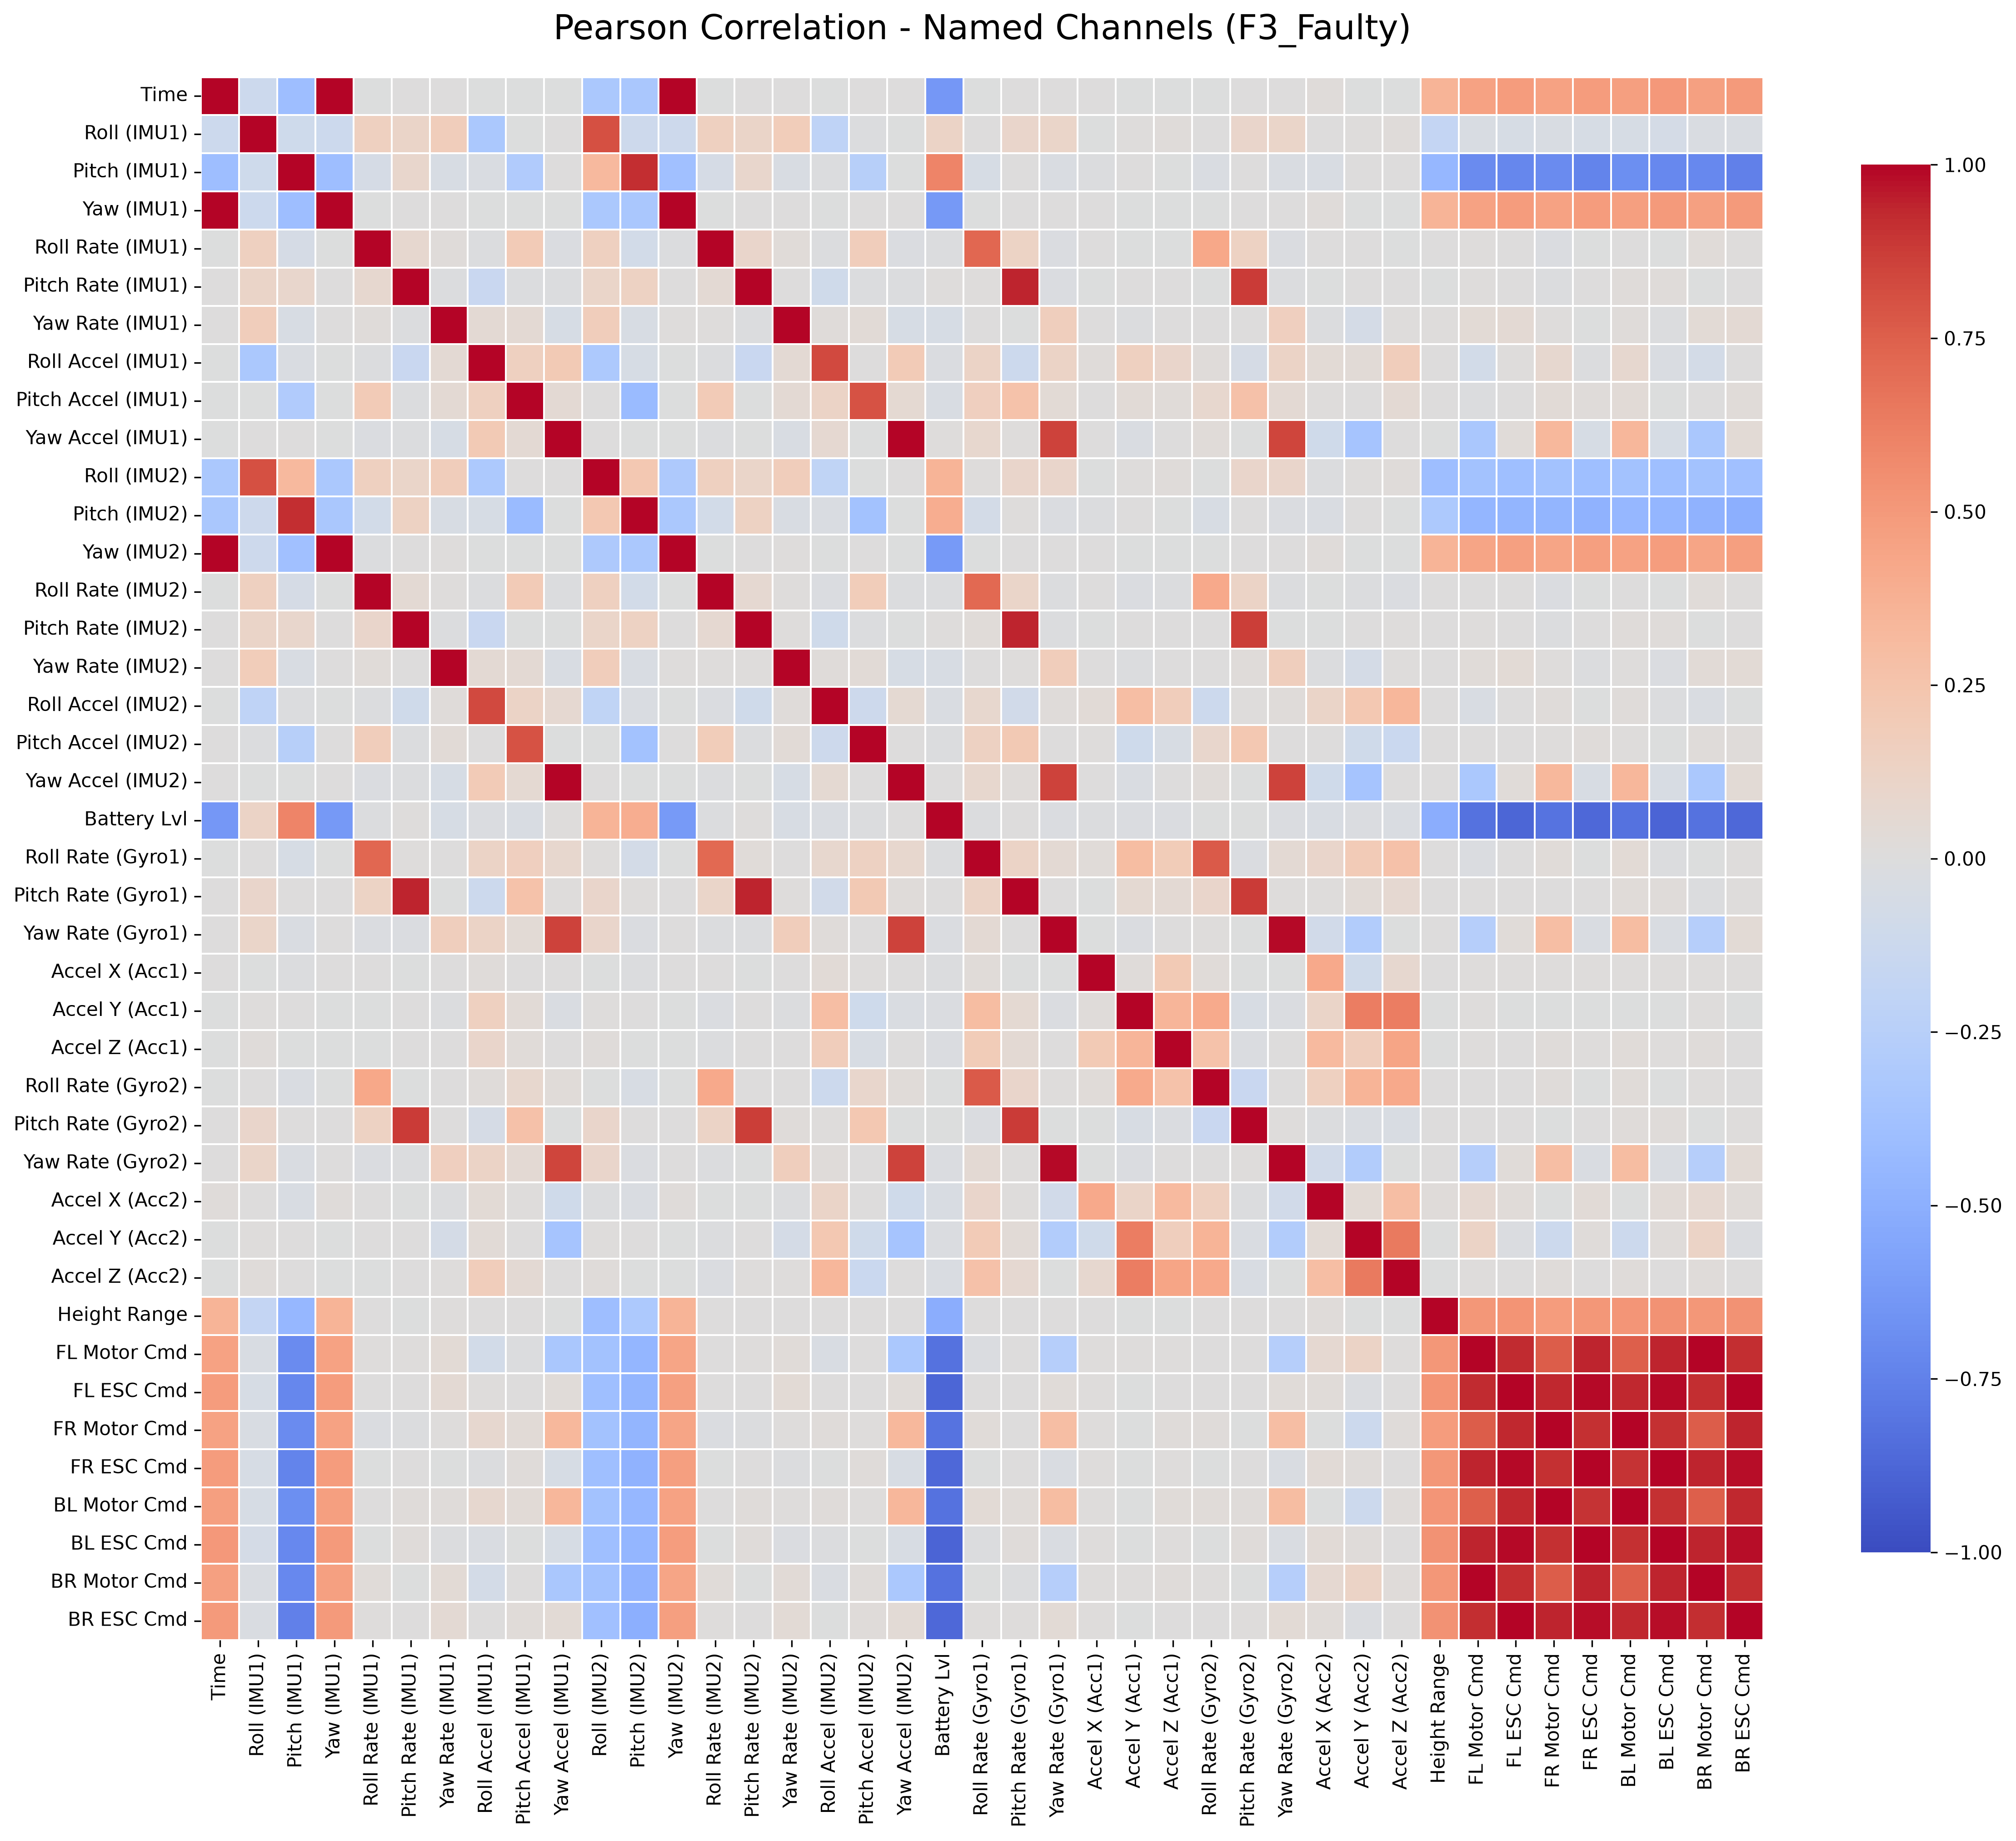

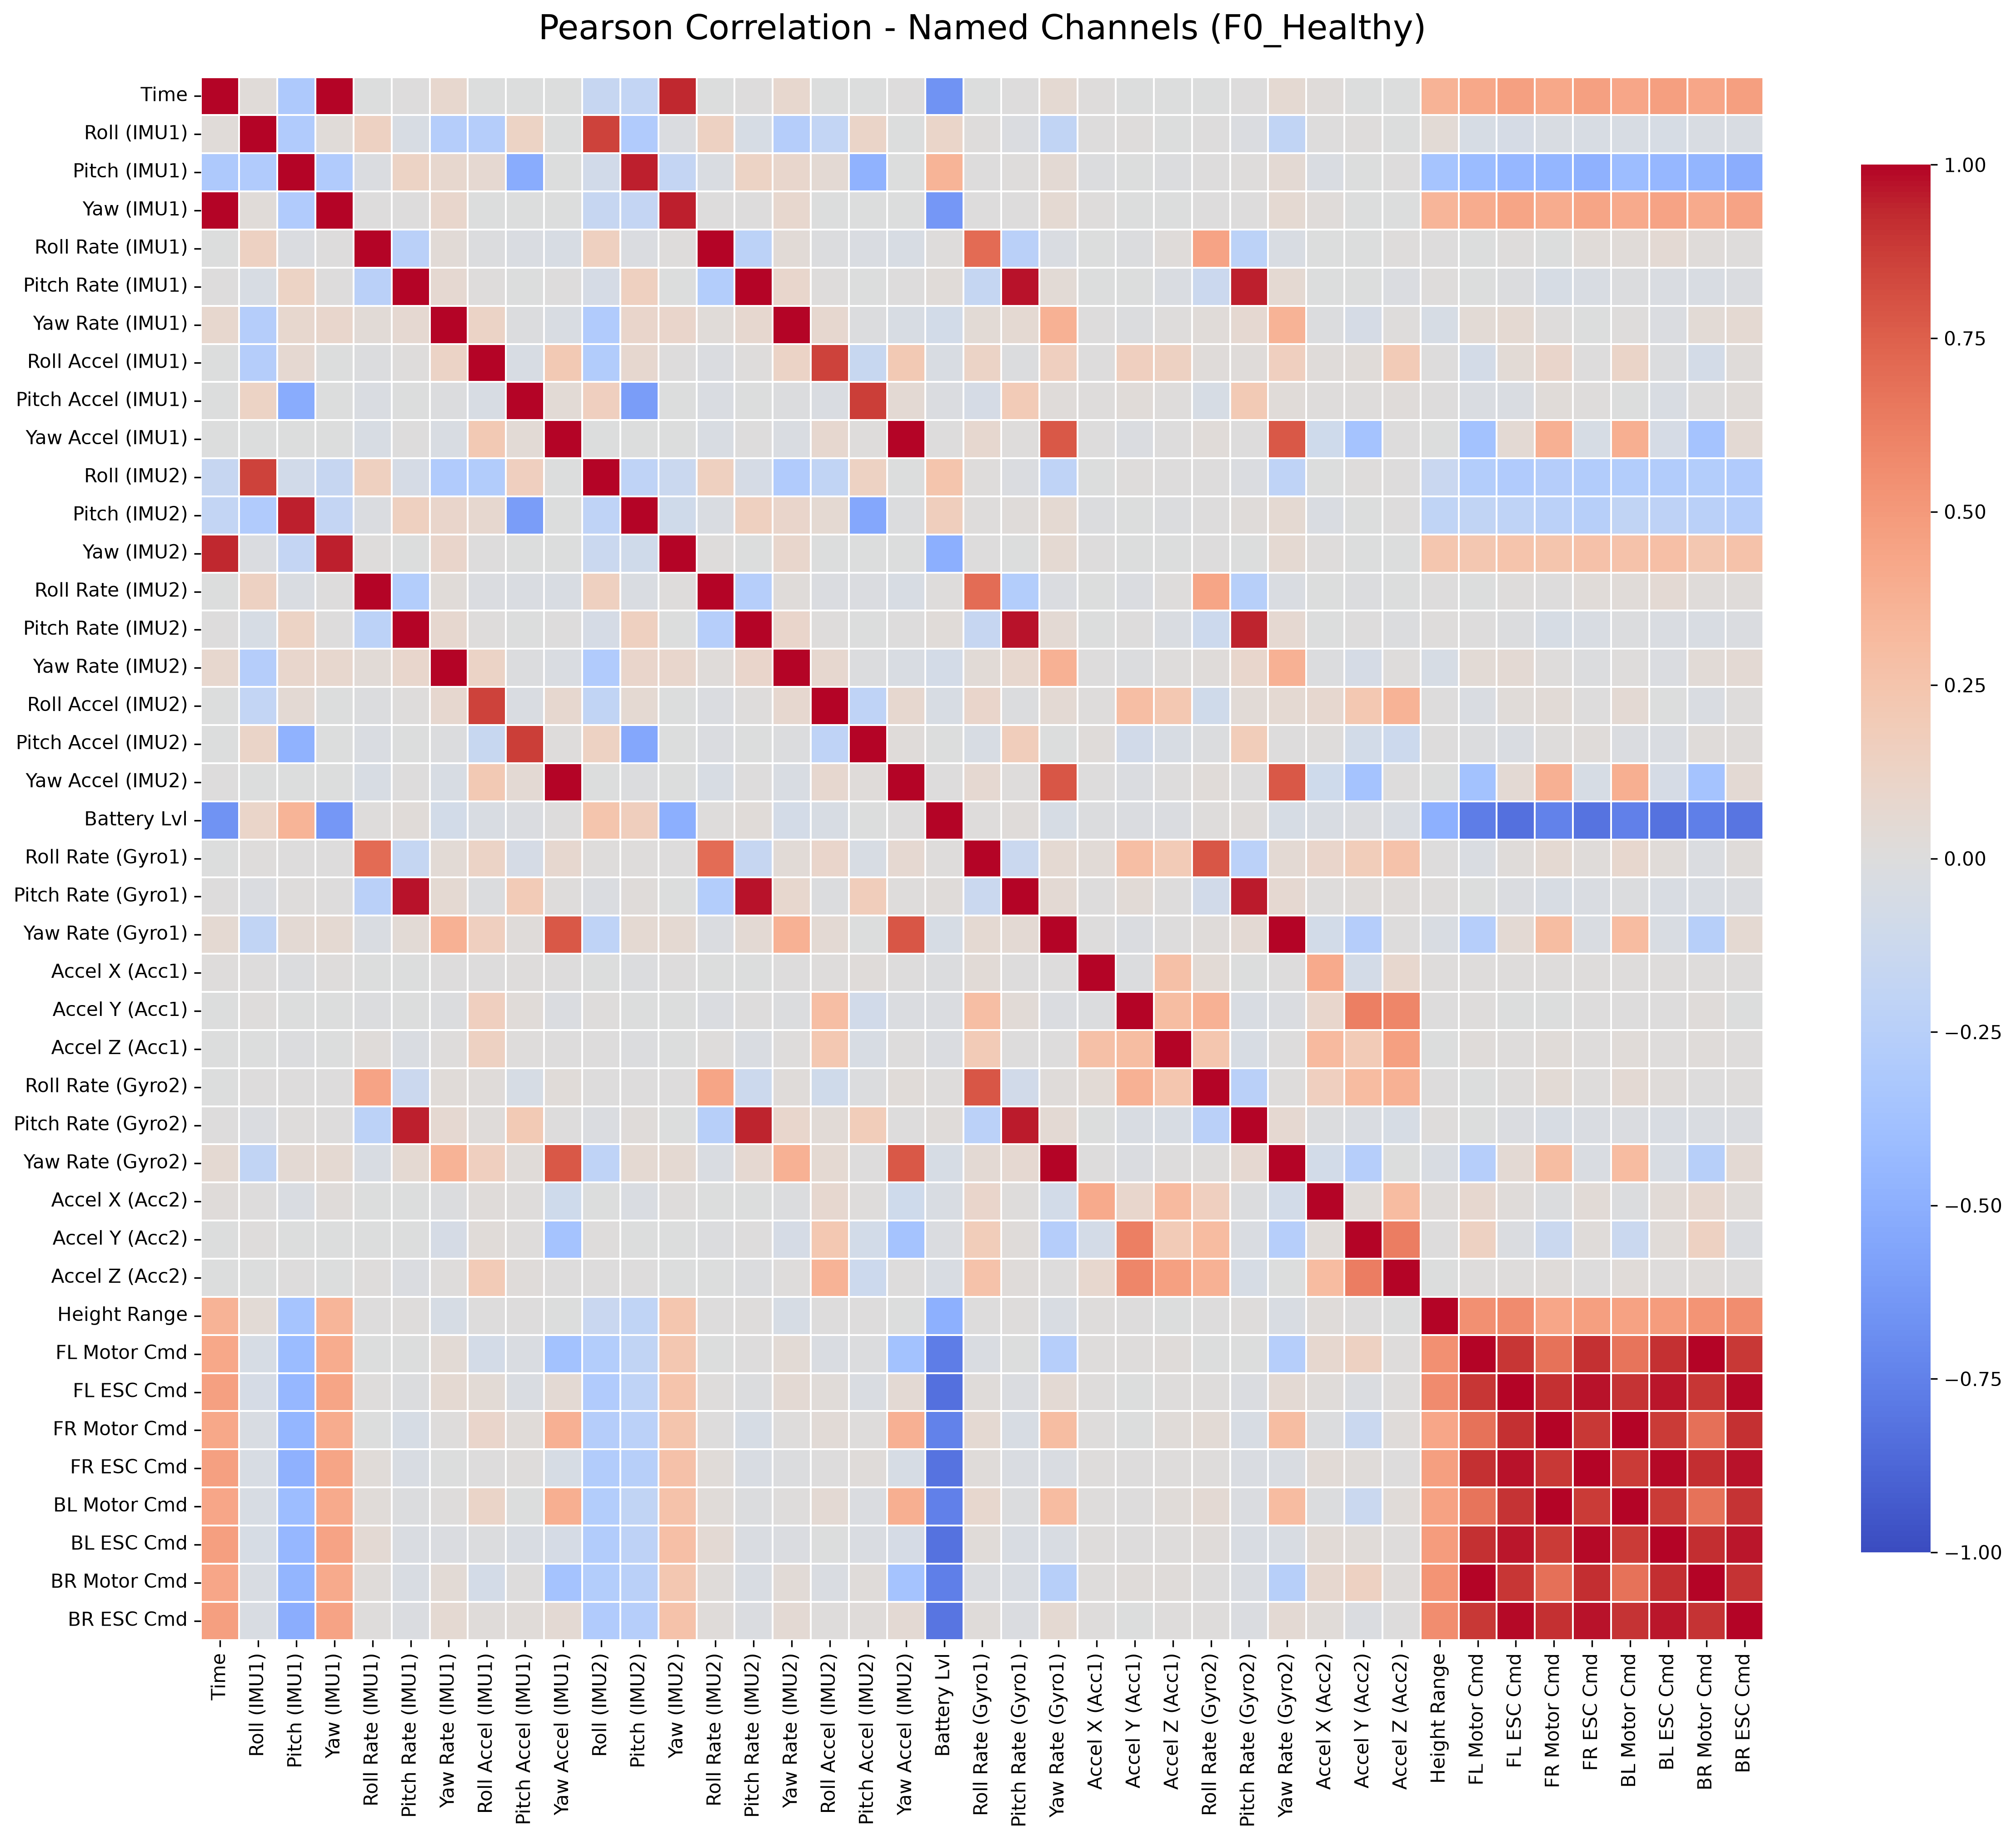

In [ ]:
data1 = sio.loadmat(r"./data")
mat1 = data1['QDrone_data']
mat1
data2 = sio.loadmat(r"./data")
mat2 = data2['QDrone_data']
plot_named_channels_correlation(mat1, "F3_Faulty")
plot_named_channels_correlation(mat2, "F0_Healthy")

In [9]:
X_t, X_f, y_data = load_multi_sensor_dataset(data_dir=drone_dir)

In [ ]:
## check the dataset

X_t

array([[[-1.06794201e-01, -9.72173959e-02, -1.16371006e-01, ...,
         -1.02005795e-01, -1.25947818e-01, -1.35524616e-01],
        [ 2.08523986e-03,  1.16620464e-02, -2.70316354e-03, ...,
          1.16620464e-02,  1.64504498e-02,  1.64504498e-02],
        [ 4.46015969e-02,  1.10827740e-02,  2.06595808e-02, ...,
          1.50596723e-03,  1.58711765e-02,  1.10827740e-02],
        ...,
        [-4.76086617e-01, -4.76083100e-01, -4.76097077e-01, ...,
         -4.76083100e-01, -4.76083100e-01, -4.76090103e-01],
        [-4.76553112e-01, -4.76549596e-01, -4.76563573e-01, ...,
         -4.76549596e-01, -4.76549596e-01, -4.76556599e-01],
        [-5.01826048e-01, -5.01822531e-01, -5.01836479e-01, ...,
         -5.01822531e-01, -5.01822531e-01, -5.01829505e-01]],

       [[-1.16371006e-01, -1.21159412e-01, -1.16371006e-01, ...,
         -1.59466639e-01, -5.41217625e-02, -7.32753798e-02],
        [ 1.64504498e-02, -2.70316354e-03,  1.16620464e-02, ...,
          4.99692746e-02, -5.05871959e

In [11]:
X_f

array([[[1.14158764e-01, 4.03577928e-04, 2.34862513e-04, ...,
         5.21299546e-04, 2.34862513e-04, 4.03577928e-04],
        [1.53491171e-02, 8.80254200e-04, 1.04443301e-04, ...,
         1.84711796e-04, 1.04443301e-04, 8.80254200e-04],
        [1.58376582e-02, 9.70133464e-04, 4.12113266e-04, ...,
         2.83799105e-04, 4.12113266e-04, 9.70133464e-04],
        ...,
        [4.76082712e-01, 3.00286416e-07, 2.29432160e-07, ...,
         3.72423443e-07, 2.29432160e-07, 3.00286416e-07],
        [4.76549208e-01, 3.00286416e-07, 2.29432160e-07, ...,
         3.72423443e-07, 2.29432160e-07, 3.00286416e-07],
        [5.01822114e-01, 3.00255351e-07, 2.29806687e-07, ...,
         3.72492536e-07, 2.29806687e-07, 3.00255351e-07]],

       [[1.15149960e-01, 3.94162576e-04, 3.08657007e-04, ...,
         9.83818318e-05, 3.08657007e-04, 3.94162576e-04],
        [1.62206050e-02, 2.98336381e-04, 4.92878724e-04, ...,
         6.88134634e-04, 4.92878724e-04, 2.98336381e-04],
        [1.39510268e-02, 

In [12]:
y_data

array([0, 0, 0, ..., 3, 3, 3], shape=(9992,))

In [ ]:
## dataset class
class VibrationDataset(Dataset):
    def __init__(self, time_X, freq_X, y):
        self.time_X = torch.from_numpy(time_X).float()
        self.freq_X = torch.from_numpy(freq_X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.time_X[idx], self.freq_X[idx], self.y[idx]


In [ ]:
## causal convolutions 
## useful for preventing model cheating by seeing into future 
class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, dilation=1):
        super().__init__()
        self.causal_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=0,
            dilation=dilation,
            bias=True
        )

    def forward(self, x):
        x = F.pad(x, (self.causal_padding, 0))
        return self.conv(x)


In [ ]:
## layernormalization
class ChannelLayerNorm1d(nn.Module):
    def __init__(self, num_channels, eps):
        super().__init__()
        self.norm = nn.LayerNorm(num_channels, eps)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.norm(x)
        return x.transpose(1, 2)

In [ ]:
## dual branch time frequency convolutions
## useful for extracting time and frequency features simultaneously
class DualBranchTFCNN(nn.Module):
    def __init__(self, in_channels, num_classes, model_variant, eps):
        super().__init__()

        variant_map = {
            1: (16, 32),
            2: (32, 64),
            3: (64, 128)
        }
        c1, c2 = variant_map[model_variant]

        self.time_branch = nn.Sequential(
            CausalConv1d(in_channels, c1, kernel_size=7, stride=1),
            nn.ReLU(),
            ChannelLayerNorm1d(c1, eps),
            nn.AvgPool1d(kernel_size=4, stride=4),
            CausalConv1d(c1, c2, kernel_size=5, stride=1),
            nn.ReLU(),
            ChannelLayerNorm1d(c2, eps),
            nn.AvgPool1d(kernel_size=4, stride=4),
            nn.AdaptiveAvgPool1d(1)

        )

        self.freq_branch = nn.Sequential(
            nn.Conv1d(in_channels, c1, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            ChannelLayerNorm1d(c1, eps),
            nn.AvgPool1d(kernel_size=4, stride=4),
            nn.Conv1d(c1, c2, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            ChannelLayerNorm1d(c2, eps),
            nn.AvgPool1d(kernel_size=4, stride=4),
            nn.AdaptiveAvgPool1d(1)

        )

        self.fc = nn.Linear(c2 * 2, num_classes)


    def forward(self, time_x, freq_x):
        t_feats = self.time_branch(time_x).squeeze(-1)
        f_feats = self.freq_branch(freq_x).squeeze(-1)

        fused_features = torch.cat((t_feats, f_feats), dim=1)

        logits = self.fc(fused_features)
        return logits


In [ ]:
## train test split

X_time_train, X_time_test, X_freq_train, X_freq_test, y_train, y_test = train_test_split(X_t, X_f, y_data, test_size=0.20, random_state=42, stratify=y_data)

In [18]:
train_dataset = VibrationDataset(X_time_train, X_freq_train, y_train)
test_dataset = VibrationDataset(X_time_test, X_freq_test, y_test)

In [19]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [20]:
model = DualBranchTFCNN(in_channels=X_t.shape[1],num_classes=num_classes,model_variant=model_variant, eps=eps).to(device)

In [21]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [22]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

In [ ]:
## training loop

def train_and_evaluate(model, train_loader, test_loader, device, epochs, optimizer, loss_fn):

    print(f"\n--- Initialized Dual Branch TFCNN Model {model_variant} ---")
    print(f"Total Learnable Parameters: {count_parameters(model)} Device: {device}")


    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for t_inputs, f_inputs, targets in train_loader:
            t_inputs, f_inputs, targets = t_inputs.to(device), f_inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            logits = model(t_inputs, f_inputs)
            loss = loss_fn(logits, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * t_inputs.size(0)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == targets).sum().item()
            total += t_inputs.size(0)

        train_loss = running_loss / total
        train_acc = (correct / total) * 100.0

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for t_inputs, f_inputs, targets in test_loader:
                t_inputs, f_inputs, targets = t_inputs.to(device), f_inputs.to(device), targets.to(device)
                v_logits = model(t_inputs, f_inputs)
                v_loss = loss_fn(v_logits, targets)
                val_loss += v_loss.item() * t_inputs.size(0)
                v_preds = torch.argmax(v_logits, dim=1)
                val_correct += (v_preds == targets).sum().item()
                val_total += t_inputs.size(0)

            val_loss /= val_total
            val_acc = (val_correct / val_total) * 100

        print(f"Epoch {epoch}: Train_loss :{train_loss:.4f} | Val_loss: {val_loss:.4f} | Train_accuracy: {train_acc:.4f} | Val_accuracy: {val_acc:.4f}")

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)


    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
         for t_inputs, f_inputs, targets in test_loader:
            t_inputs = t_inputs.to(device)
            f_inputs = f_inputs.to(device)
            f_logits = model(t_inputs, f_inputs)
            preds = torch.argmax(f_logits, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(targets.cpu().numpy())

    test_acc = accuracy_score(all_targets, all_preds) * 100.0

    print(f"\nFinal Test Accuracy Dual Branch TFCNN Model {model_variant}: {test_acc:.4f}")
    
    return model, history

In [ ]:
## plot training and validation loss and accuracy curves

def plot_learning_curves(history):

    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize = (14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label = 'Training_loss', linewidth=2)
    plt.plot(epochs, history['val_loss'], label = 'Val_loss', linewidth=2, linestyle='--')
    plt.title('Training and Validation Loss Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':',alpha=0.7)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], label = 'Training_acc', linewidth=2)
    plt.plot(epochs, history['val_acc'], label = 'Val_acc', linewidth=2, linestyle='--')
    plt.title('Training and Validation Accuracy Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [25]:
trained_model, hist = train_and_evaluate(model=model, train_loader=train_loader, test_loader=test_loader, epochs=epochs, device=device, optimizer=optimizer, loss_fn=loss_fn)


--- Initialized Dual Branch TFCNN Model 1 ---
Total Learnable Parameters: 7140 Device: cpu
Epoch 1: Train_loss :1.3604 | Val_loss: 1.3092 | Train_accuracy: 35.1307 | Val_accuracy: 47.5238
Epoch 2: Train_loss :1.2617 | Val_loss: 1.2209 | Train_accuracy: 45.5774 | Val_accuracy: 52.0260
Epoch 3: Train_loss :1.1605 | Val_loss: 1.1212 | Train_accuracy: 53.7721 | Val_accuracy: 56.7284
Epoch 4: Train_loss :1.0465 | Val_loss: 1.0043 | Train_accuracy: 59.7398 | Val_accuracy: 61.5308
Epoch 5: Train_loss :0.9318 | Val_loss: 0.8987 | Train_accuracy: 64.1812 | Val_accuracy: 65.1826
Epoch 6: Train_loss :0.8201 | Val_loss: 0.7926 | Train_accuracy: 69.3732 | Val_accuracy: 69.8349
Epoch 7: Train_loss :0.7289 | Val_loss: 0.7145 | Train_accuracy: 72.9388 | Val_accuracy: 72.4362
Epoch 8: Train_loss :0.6593 | Val_loss: 0.6569 | Train_accuracy: 75.7538 | Val_accuracy: 74.8874
Epoch 9: Train_loss :0.6159 | Val_loss: 0.6371 | Train_accuracy: 77.2926 | Val_accuracy: 74.7374
Epoch 10: Train_loss :0.5844 | Val_

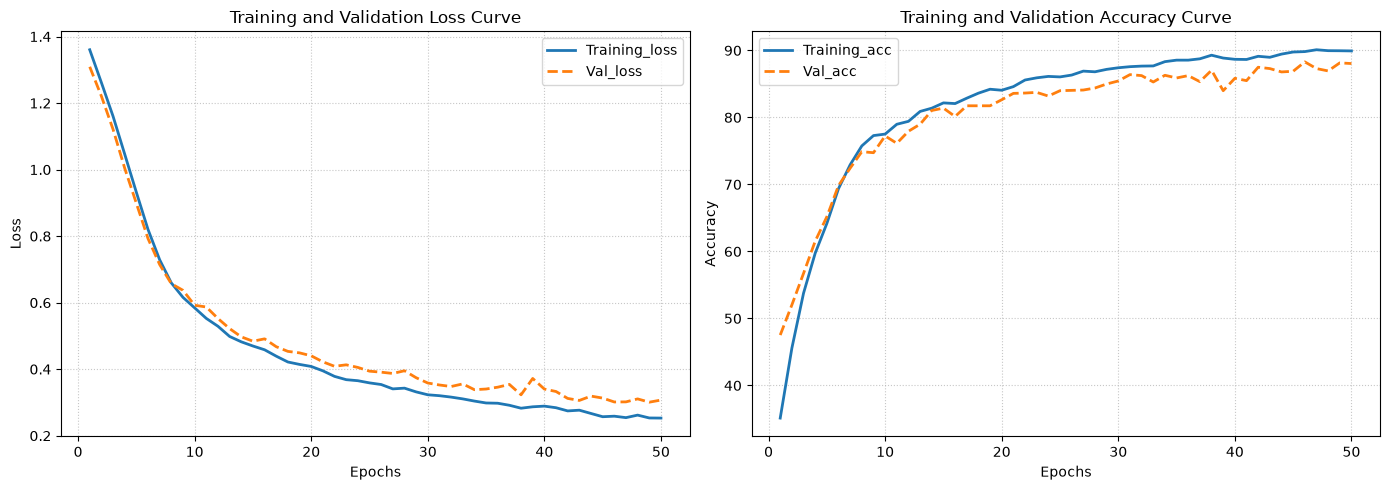

In [26]:
plot_learning_curves(history=hist)

In [ ]:
## plot t-SNE clusters brought down to 2D

def plot_tsne_clusters(model, test_loader, device):
    model.eval()
    all_features = []
    all_targets = []
    print("Extracting features....")

    with torch.no_grad():
        for t_inputs, f_inputs, targets in test_loader:
            t_inputs = t_inputs.to(device)
            f_inputs = f_inputs.to(device)

            time_features = model.time_branch(t_inputs).squeeze(-1)
            freq_features = model.freq_branch(f_inputs).squeeze(-1)

            features = torch.cat((time_features, freq_features), dim=1)

            all_features.append(features.cpu().numpy())
            all_targets.append(targets.cpu().numpy())


    all_features = np.concatenate(all_features, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    print("Computing t-SNE....Please wait")

    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
    features_2d = tsne.fit_transform(all_features)
    
    print("Plotting the clusters....")
    plt.figure(figsize=(12, 8))

    class_names = ["F0 (Healthy)", "F1 (Edge cut)", "F2 (Crack)", "F3 (Surface Cut)"]
    colors = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728']

    for class_idx, (class_name, color) in enumerate(zip(class_names, colors)):

        indices = (all_targets == class_idx)

        plt.scatter(features_2d[indices, 0], features_2d[indices, 1],c=color,label=class_name,alpha=0.7,edgecolors='w',linewidth=0.5)

    plt.title('t-SNE Visualization of DronePropA Deep Features', fontsize=14, fontweight='bold')
    plt.xlabel('t-SNE Dimension 1', fontsize=12)
    plt.ylabel('t-SNE Dimension 2', fontsize=12)
    plt.legend(title='Propeller States', title_fontsize='13',fontsize='11')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

Extracting features....
Computing t-SNE....Please wait
Plotting the clusters....


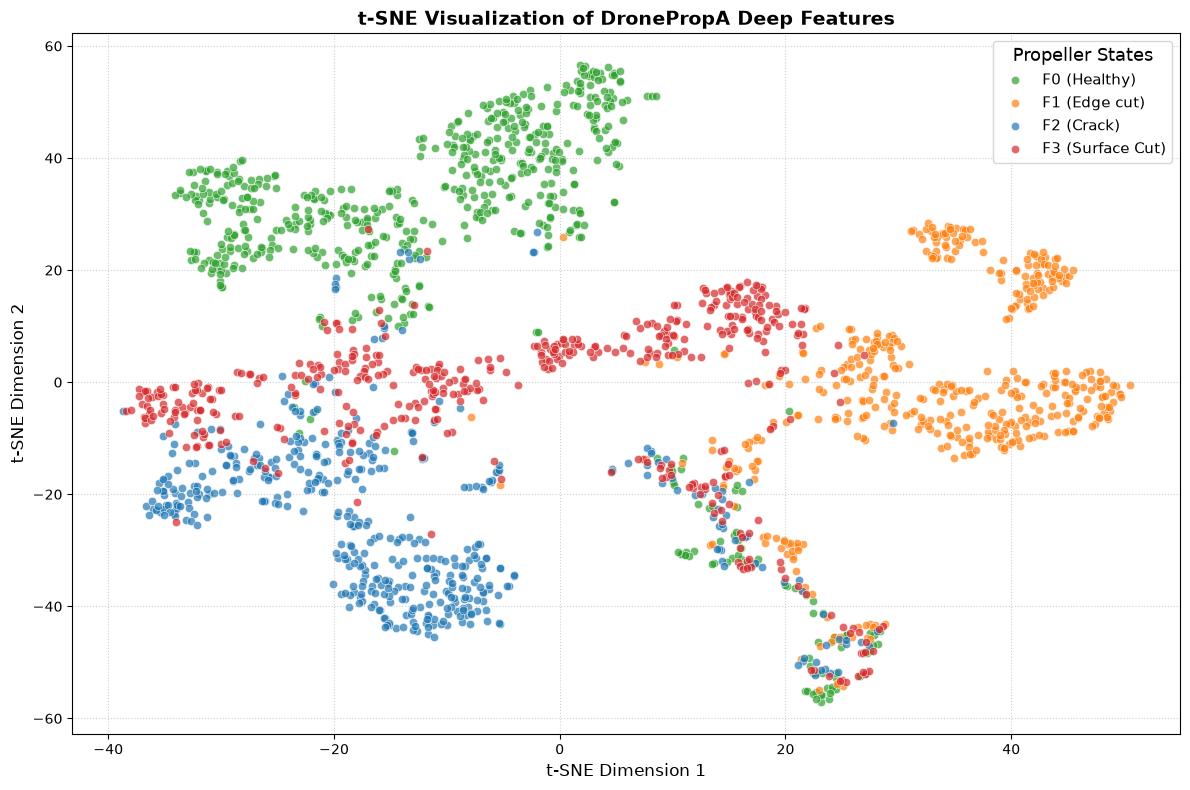

In [28]:
plot_tsne_clusters(trained_model, test_loader, device)

In [ ]:
## plot confusion matrix and classification report graphically

def plot_colorful_metrics(y_true, y_pred):
    class_names = ["F0 (Healthy)", "F1 (Edge Cut)", "F2 (Crack)", "F3 (Surface Cut)"]

    # confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(8, 6), dpi=300)

    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                square=True, linewidths=0.5, cbar_kws={"shrink": .8})
    
    plt.title('Confusion Matrix - Dual-Branch TF-CNN', fontsize=16, pad=15)
    plt.xlabel('Predicted Fault Class', fontsize=12)
    plt.ylabel('True Fault Class', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # classification report
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose()
    
    # Separate the 0-1 metrics from the massive 'support' values to protect the color scale
    df_metrics = df_report.drop('support', axis=1)
    
    plt.figure(figsize=(8, 6), dpi=300)
    # vmin=0.0 and vmax=1.0 strictly lock the color scale to standard percentage bounds
    sns.heatmap(df_metrics, annot=True, fmt='.4f', cmap='viridis', 
                vmin=0.0, vmax=1.0, square=True, linewidths=0.5, cbar_kws={"shrink": .8})
    
    plt.title('Classification Report Metrics', fontsize=16, pad=15)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    plt.show()


Running quick inference to extract predictions...


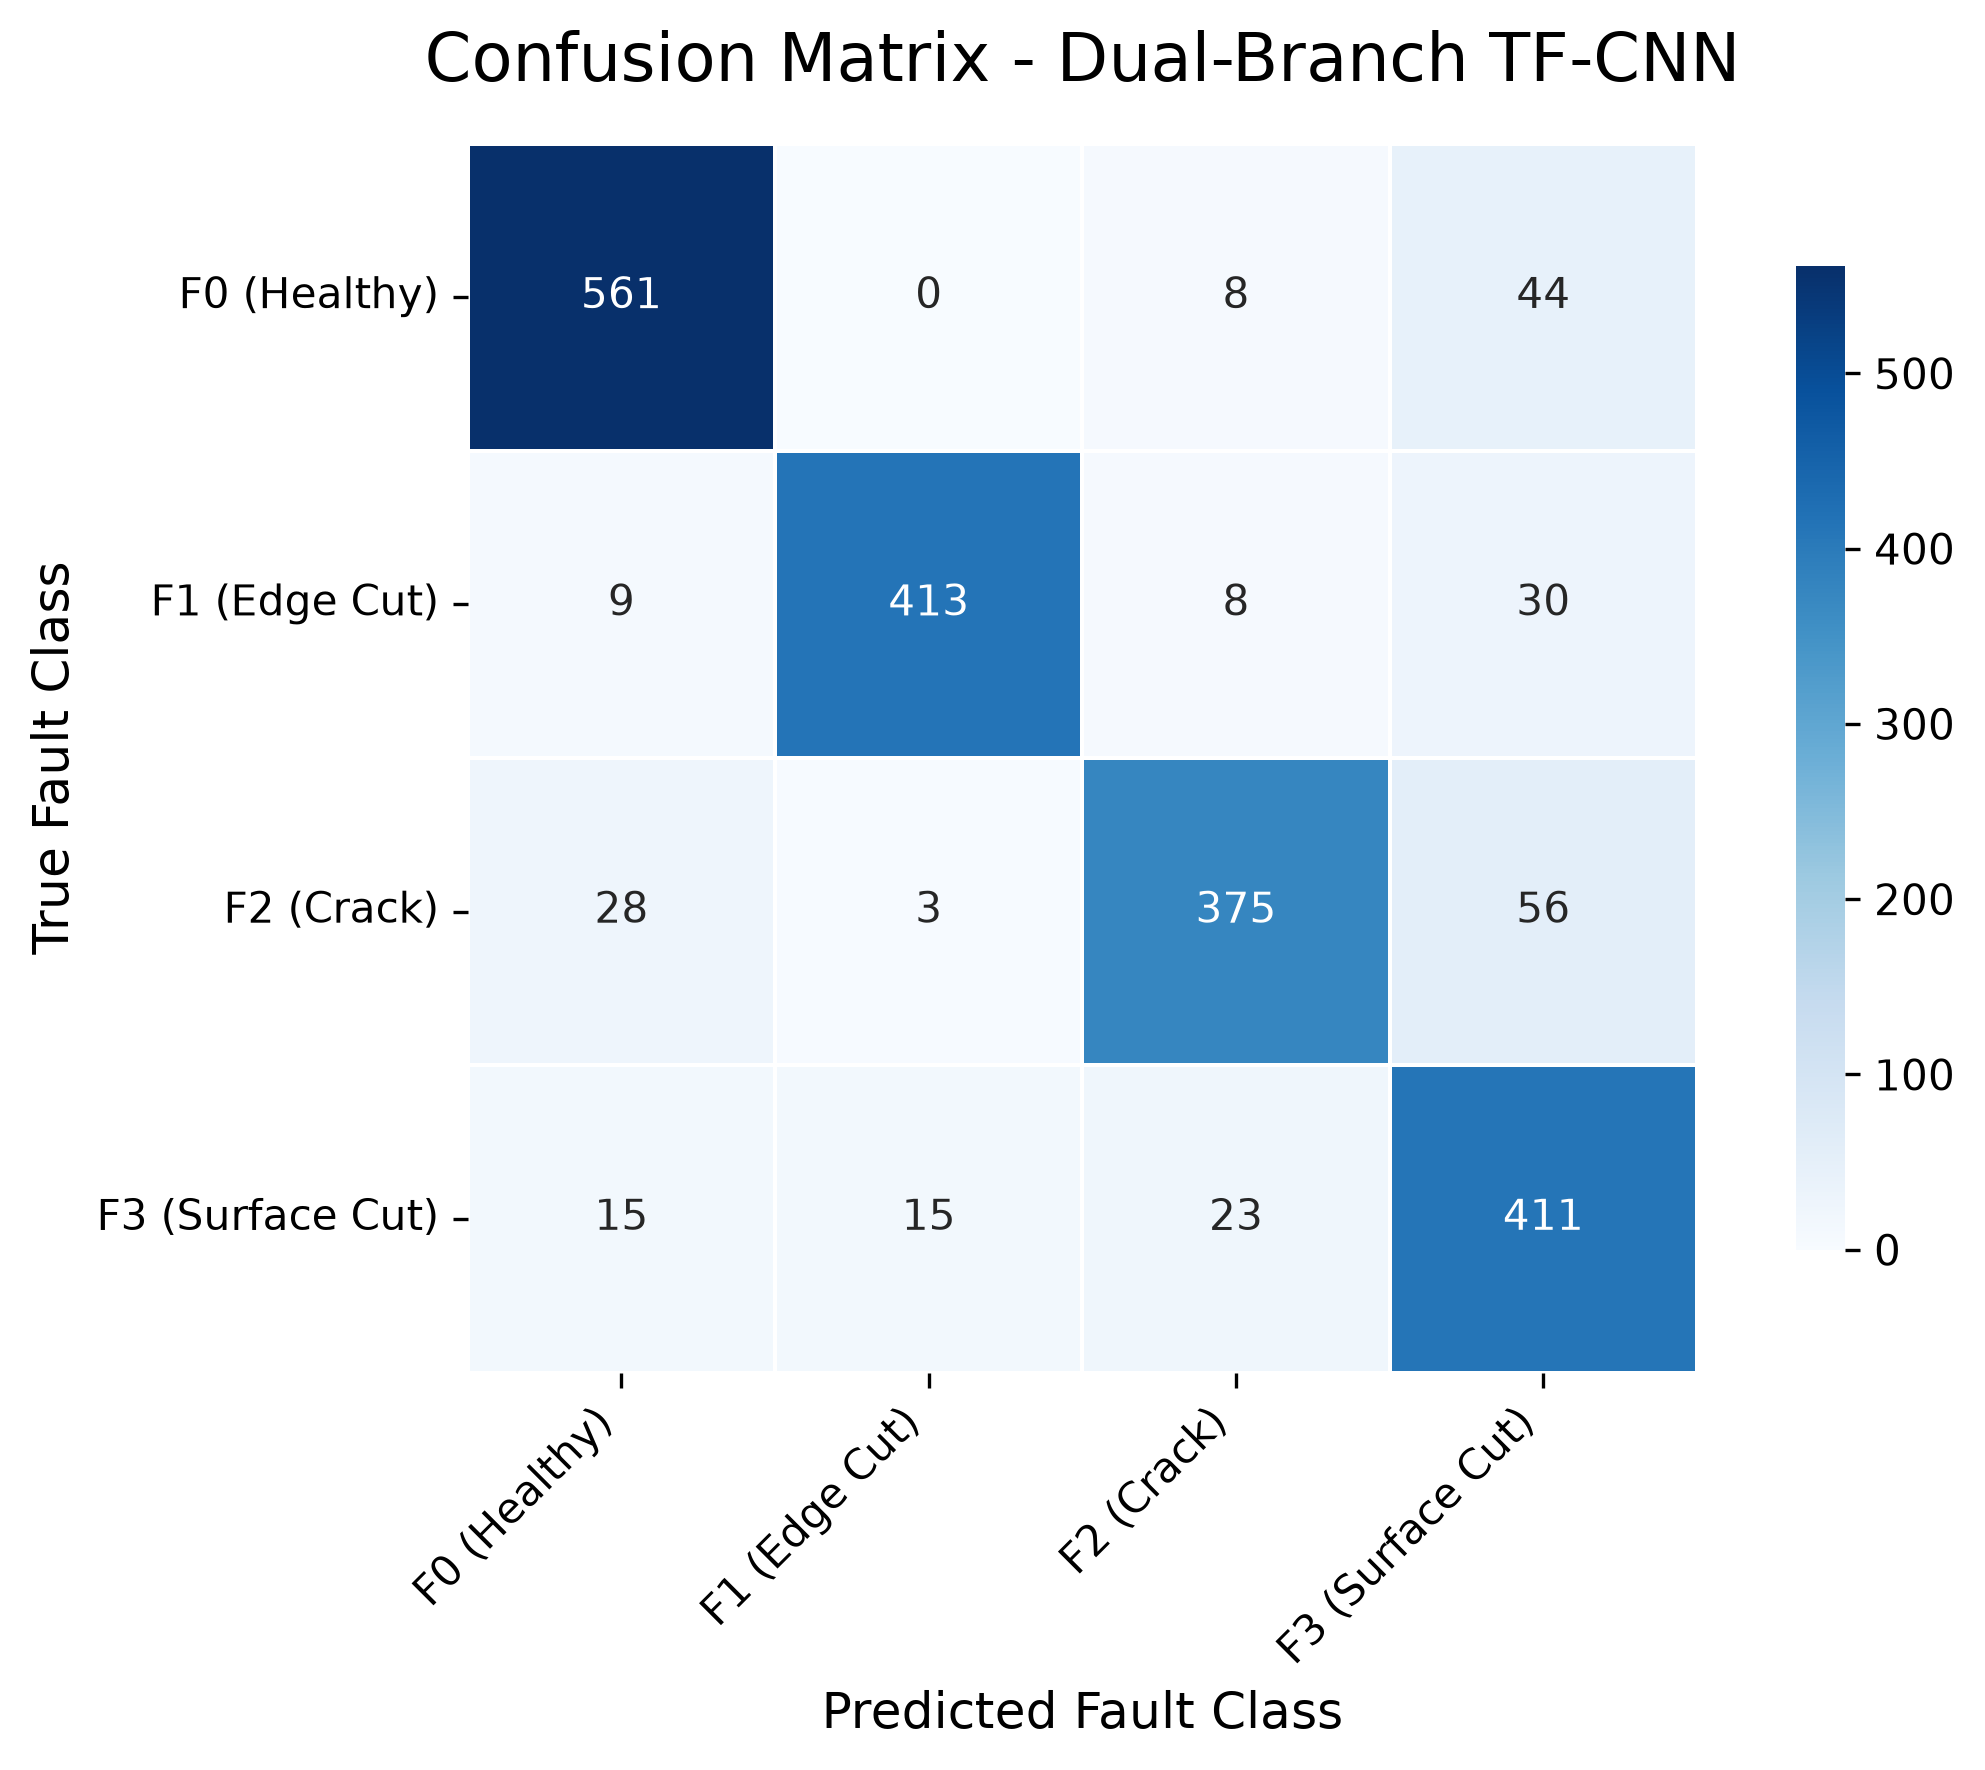

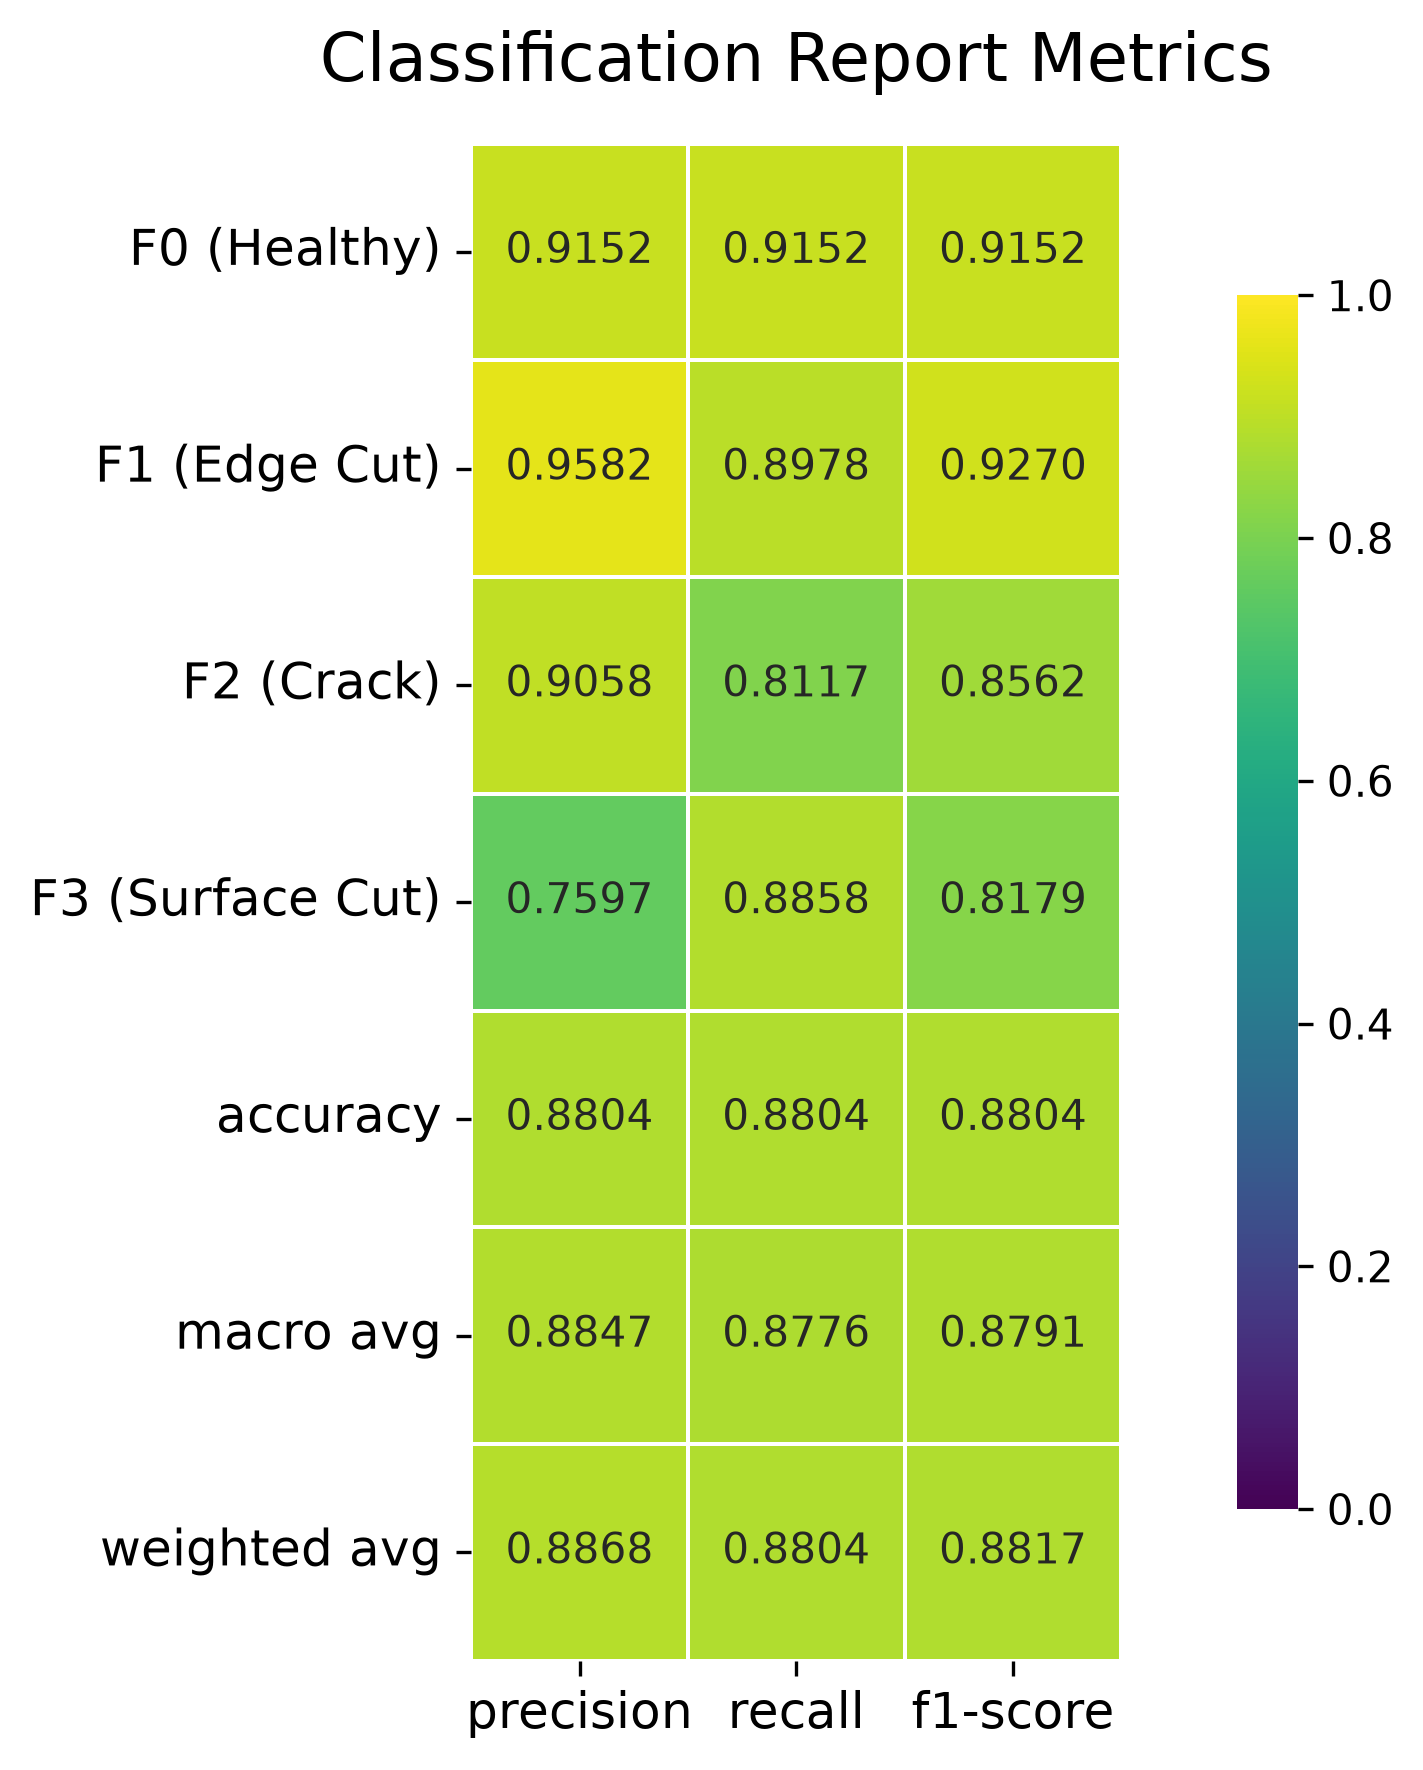

In [30]:
def get_test_predictions(model, test_loader, device):
    print("Running quick inference to extract predictions...")
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for t_inputs, f_inputs, targets in test_loader:
            t_inputs = t_inputs.to(device)
            f_inputs = f_inputs.to(device)
            
            # Forward pass only
            logits = model(t_inputs, f_inputs)
            preds = torch.argmax(logits, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    return np.array(all_targets), np.array(all_preds)

# 1. Grab the predictions using your already-trained model
y_true, y_pred = get_test_predictions(trained_model, test_loader, device)

# 2. Feed them directly into the plotting function
plot_colorful_metrics(y_true, y_pred)